In [31]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [24]:
df = pd.read_pickle("./data_features_clustering")
outliers = pd.read_pickle("./clustering_outliers")
df_len = len(df)
df = df[~df["id"].isin(outliers["id"])]
print(f"removed {df_len - len(df)}")
pd.to_pickle(df, "./data_features_wo_outliers")

removed 101


In [25]:
scaler = StandardScaler()
features = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                    "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
print(len(features.columns))
non_binary_cols = features.columns[features.nunique() > 2]
scaled_features = features.copy()
scaled_features[non_binary_cols] = scaler.fit_transform(features[non_binary_cols])


11


Use PCA and subsampling to reduce the size of the dataset. 8 GB of memory are not enough to cluster 65k entries with O(n^2) efficiency.

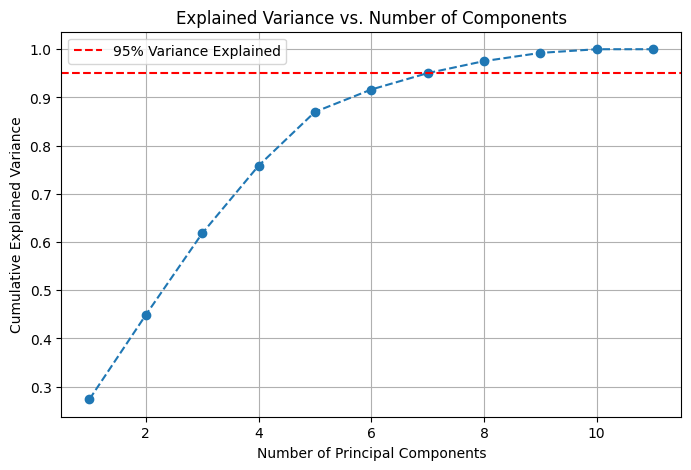

In [27]:
pca = PCA()
pca.fit(scaled_features)

# Cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Number of Components')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Explained')
plt.legend(loc='best')
plt.grid()
plt.show()

In [ ]:
pca = PCA(n_components = 7)
reduced_features = pca.fit_transform(scaled_features)

num_components = reduced_features.shape[1]
column_names = [f'PC{i+1}' for i in range(num_components)]

reduced_features = pd.DataFrame(reduced_features, columns=column_names)
print(f"length of df {len(reduced_features)}")

subsampled_df = reduced_features.sample(n=30_000, random_state=42)
print("reduce to 30000")


length of df 63720
reduce to 30_000


In [30]:
agglo_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
clusters = agglo_model.fit_predict(subsampled_df)

In [ ]:
Z = linkage(subsampled_df, method='ward')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title("Dendrogram for Agglomerative Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.show()